# 04 — Random Forest vs Decision Tree (Supporting Exercise)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

The single Decision Tree (`03_decision_tree_review.ipynb`) only slightly improved on Linear Regression, and it showed some
overfitting (training R² 0.52 vs test R² 0.27).

**Random Forest** combines many Decision Trees and averages their predictions. The goal is to see whether many trees
perform better and more consistently than one Decision Tree.

- **Target:** `duration_days`, the recorded activity span (same as before)
- **Features:** `events_per_case`, `unique_activities`, `unique_resources` (same as before)

## 2. Same Data

Same dataset and same completed-case logic as the previous notebooks.

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))

Completed cases: 956


> **Supporting experiment.** These features describe the **whole finished case**, so they are only known after the
> case ends. This is a regression learning exercise, **not** an early-warning model.

In [3]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

## 3. Same Train/Test Split

Exactly the same split as before, so all models are tested on the same 192 cases.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 4. Random Forest Model

- `n_estimators=100` means **100 Decision Trees**. Each tree is trained on a slightly different random sample of the training cases.
- `max_depth=4` limits how deep each tree can grow (the same depth as the single tree in notebook 03).
- The final prediction is the **average** of the 100 tree predictions.

In [5]:
model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## 5. Evaluate

Same metrics as before: **MAE**, **RMSE** and **R²**. I also compare training R² with test R² to check for overfitting.

In [6]:
mae = mean_absolute_error(y_test, y_pred)
rmse = mean_squared_error(y_test, y_pred) ** 0.5
r2 = r2_score(y_test, y_pred)

train_r2 = r2_score(y_train, model.predict(X_train))
test_r2 = r2

print(f"Random Forest MAE: {mae:.2f} days")
print(f"Random Forest RMSE: {rmse:.2f} days")
print(f"Random Forest R²: {r2:.2f}")
print()
print(f"Training R²: {train_r2:.2f}")
print(f"Test R²: {test_r2:.2f}")

Random Forest MAE: 52.00 days
Random Forest RMSE: 109.60 days
Random Forest R²: 0.44

Training R²: 0.52
Test R²: 0.44


## 6. Check Negative Predictions

In [7]:
print(f"Minimum predicted duration: {y_pred.min():.2f} days")
print("Predictions below zero:", (y_pred < 0).sum())

Minimum predicted duration: 56.07 days
Predictions below zero: 0


## 7. Feature Importance

Feature importance shows which variables the trees used most when making their splits (averaged over the 100 trees).
It does **not** mean that a feature *causes* longer or shorter cases.

In [8]:
importance = pd.DataFrame({
    "feature": X.columns,
    "importance": model.feature_importances_
})
importance

,feature,importance
0,events_per_case,0.610734
1,unique_activities,0.244125
2,unique_resources,0.145142


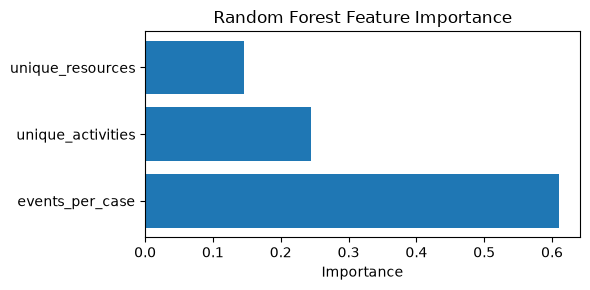

In [9]:
plt.figure(figsize=(6, 3))
plt.barh(importance["feature"], importance["importance"])
plt.title("Random Forest Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 8. Actual vs Predicted

Points on the dashed line would be perfect predictions.

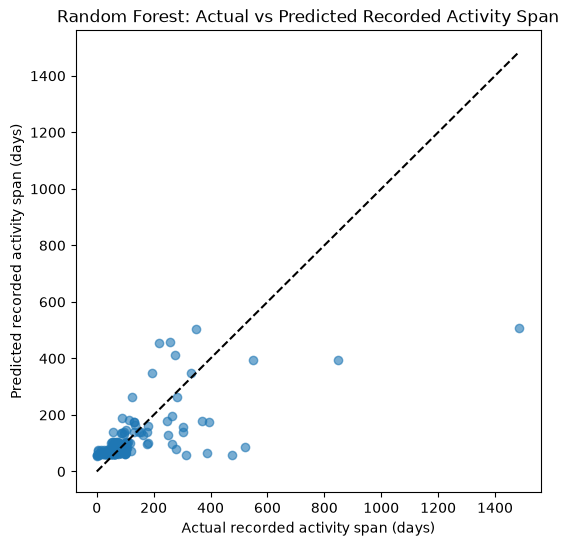

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([0, y_test.max()], [0, y_test.max()], linestyle="--", color="black")
plt.title("Random Forest: Actual vs Predicted Recorded Activity Span")
plt.xlabel("Actual recorded activity span (days)")
plt.ylabel("Predicted recorded activity span (days)")
plt.show()

## 9. Compare All Models

Same 764 training and 192 test cases for every approach. Linear Regression and the Decision Tree are trained again here
with the same settings as notebooks 02 and 03, so no results are copied by hand.

In [11]:
linear_model = LinearRegression().fit(X_train, y_train)
tree_model = DecisionTreeRegressor(max_depth=4, random_state=42).fit(X_train, y_train)

mean_train = [y_train.mean()] * len(y_train)
median_train = [y_train.median()] * len(y_train)
approaches = [
    ("Mean baseline", mean_train, [y_train.mean()] * len(y_test)),
    ("Median baseline", median_train, [y_train.median()] * len(y_test)),
    ("Linear Regression", linear_model.predict(X_train), linear_model.predict(X_test)),
    ("Decision Tree", tree_model.predict(X_train), tree_model.predict(X_test)),
    ("Random Forest", model.predict(X_train), y_pred),
]

**Compare all approaches on the same 192 test cases.** The loop calculates the same metrics for each approach; Train R² is shown next to Test R² as a simple check for overfitting.

In [12]:
# the same metrics for every approach, on the same 192 test cases
rows = []
for name, pred_train, pred_test in approaches:
    rows.append({
        "Model": name,
        "Test MAE": mean_absolute_error(y_test, pred_test),
        "Test RMSE": mean_squared_error(y_test, pred_test) ** 0.5,
        "Test R²": r2_score(y_test, pred_test),
        "Train R²": r2_score(y_train, pred_train),
    })
comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(2)

,Test MAE,Test RMSE,Test R²,Train R²
Model,,,,
Mean baseline,71.98,147.26,-0.00,0.00
Median baseline,64.42,153.00,-0.08,-0.09
Linear Regression,59.01,126.02,0.26,0.18
Decision Tree,58.73,125.50,0.27,0.52
Random Forest,52.00,109.60,0.44,0.52


## 10. Simple Interpretation

1. **Did Random Forest improve MAE?** Yes: 52.00 days, compared with 58.73 (Decision Tree), 59.01 (Linear Regression)
   and 64.42 (median baseline).
2. **Did it improve RMSE?** Yes: 109.60 days, compared with 125.50 (Decision Tree) and 126.02 (Linear Regression).
3. **Did it improve R²?** Yes: 0.44, compared with 0.27 (Decision Tree) and 0.26 (Linear Regression).
4. **Is the train/test gap smaller?** Yes, on this split: training R² 0.52 vs test R² 0.44 (a gap of 0.08), compared with
   0.52 vs 0.27 for the single tree (a gap of 0.25). The extreme over-predictions of the single tree (about 840–880 days)
   are also gone. A smaller gap on one split is a good sign, but it does not prove that overfitting is solved.
5. **Did it avoid negative predictions?** Yes. The lowest prediction is 56.07 days.
6. **Which feature is most important?** `events_per_case` (about 0.61), then `unique_activities` (about 0.24) and
   `unique_resources` (about 0.15). This shows what the trees used, not what causes long cases.
7. **Is the improvement meaningful?** On this test set it is clearly larger than the step from Linear Regression to one
   tree: R² rises from 0.27 to 0.44 and MAE falls by about 7 days. But the model is still far from perfect: the longest
   cases are strongly under-predicted (the longest test case, about 1,486 days, is predicted at about 500 days), and very
   short cases are predicted at about 56 days or more.

This result comes from **one** train/test split of 192 cases, so the exact size of the gain is uncertain. The features also
describe the completed case, so this is still a model-comparison exercise, not an early-warning model.

## 11. Next Step

Try **Gradient Boosting** (notebook 05), which builds trees step by step to correct earlier errors.